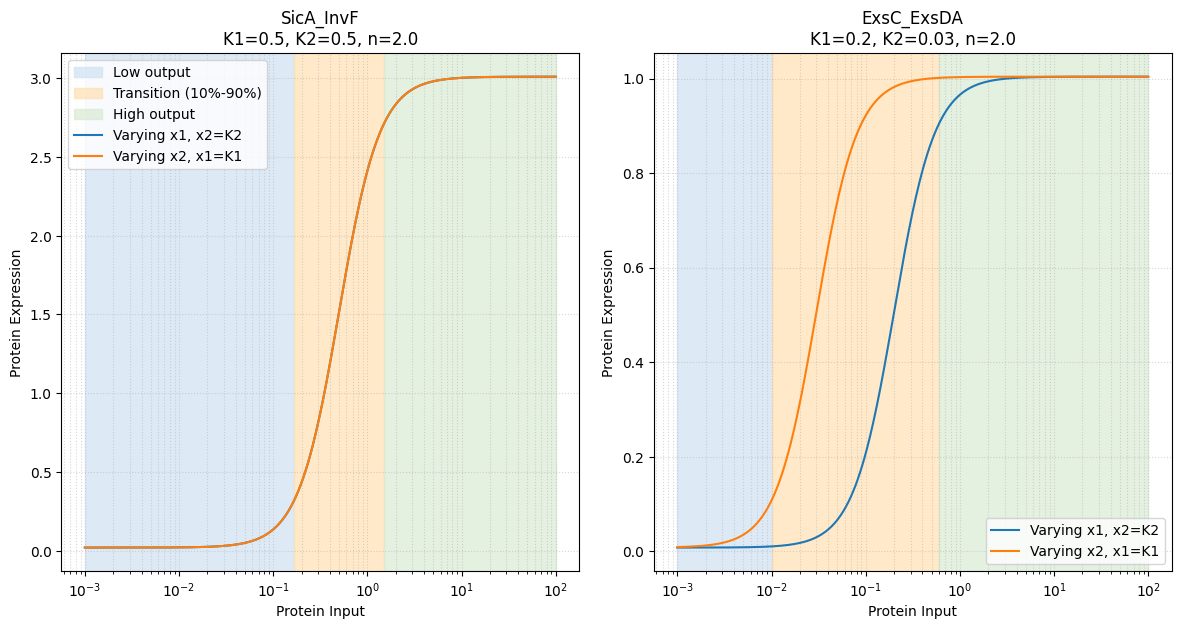

In [1]:
import csv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

with open("parsed_Eco3C3G3T3.csv", newline="") as csv_file:
    rows = list(csv.reader(csv_file))
rows[0] = [np.nan] + rows[0]
raw = pd.DataFrame(rows)

and_rows = raw[raw.iloc[:, 1] == "AND"]
gate_names = and_rows.iloc[:,  2].dropna().unique()

fig, axes = plt.subplots(1, len(gate_names), figsize=(12, 6), squeeze=False)
x = np.logspace(-3, 2, 400)

for index, gate_name in enumerate(gate_names):
    axis = axes.flat[index]
    gate_rows = and_rows[and_rows.iloc[:, 2] == gate_name]
    parameters = {}

    for _, row in gate_rows.iterrows():
        key = row.iloc[4]
        if key in {"ymin", "ymax", "K1", "K2", "n"}:
            parameters[key] = float(row.iloc[5])

    transition_factor = 9 ** (1 / parameters["n"])
    transition_min = min(parameters["K1"], parameters["K2"]) / transition_factor
    transition_max = max(parameters["K1"], parameters["K2"]) * transition_factor
    axis.axvspan(x.min(), transition_min, color="#cfe2f3", alpha=0.7,
                 label="Low output" if index == 0 else None)
    axis.axvspan(transition_min, transition_max, color="#ffe0b2", alpha=0.7,
                 label="Transition (10%-90%)" if index == 0 else None)
    axis.axvspan(transition_max, x.max(), color="#d9ead3", alpha=0.7,
                 label="High output" if index == 0 else None)

    y_x1 = parameters["ymin"] + (parameters["ymax"] - parameters["ymin"]) * (
        x**parameters["n"]
        / (parameters["K1"] ** parameters["n"] + x**parameters["n"])
    ) * (
        parameters["K2"] ** parameters["n"]
        / (parameters["K2"] ** parameters["n"] + parameters["K2"] ** parameters["n"])
    )
    y_x2 = parameters["ymin"] + (parameters["ymax"] - parameters["ymin"]) * (
        parameters["K1"] ** parameters["n"]
        / (parameters["K1"] ** parameters["n"] + parameters["K1"] ** parameters["n"])
    ) * (
        x**parameters["n"]
        / (parameters["K2"] ** parameters["n"] + x**parameters["n"])
    )

    axis.plot(x, y_x1, label="Varying x1, x2=K2", zorder=2)
    axis.plot(x, y_x2, label="Varying x2, x1=K1", zorder=2)
    axis.set_xscale("log")
    axis.set_box_aspect(1)
    axis.set_title(f"{gate_name}\nK1={parameters['K1']}, K2={parameters['K2']}, n={parameters['n']}")
    axis.set_xlabel("Protein Input")
    axis.set_ylabel("Protein Expression")
    axis.legend()
    axis.grid(True, which="both", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()